# Практична робота: Дерева рішень, ансамблі та класифікація

## Вступ

**Дерева рішень** — це один із найпопулярніших та найзрозуміліших алгоритмів машинного навчання. Уявіть, що ви граєте в гру «20 запитань»: ви ставите питання, які поступово звужують коло можливих відповідей, доки не дійдете до правильної.

Саме так працює дерево рішень! Воно будує послідовність запитань, кожне з яких розділяє дані на дві (або більше) груп, поки не буде знайдено відповідь.

### Чому дерева рішень такі популярні?

- **Інтерпретованість**: після навчання модель — це набір простих правил, які легко пояснити навіть нефахівцю.
- **Простота**: легко зрозуміти, як модель приймає рішення.
- **Універсальність**: працюють як для класифікації, так і для регресії.
- **Основа для складніших алгоритмів**: випадковий ліс (Random Forest) та XGBoost побудовані на основі дерев.

### Аналогія з реального життя

Уявіть, що ви обираєте, яку піцу замовити:

1. Ви голодні? → Якщо ні, замовляєте маленьку. Якщо так, йдете далі.
2. Ви любите м'ясо? → Якщо так, замовляєте пепероні. Якщо ні, йдете далі.
3. Ви любите гриби? → Якщо так, замовляєте з грибами. Якщо ні — «Маргариту».

Це і є дерево рішень! Кожен вузол — це запитання, кожна гілка — відповідь, а листок — кінцевий результат.

---
## Що ми сьогодні зробимо:
1. **Розберемо, як працює дерево рішень на простому прикладі** — покроково розглянемо принцип розщеплення даних та побудови правил прийняття рішень.
2. **Проілюструємо проблему перенавчання (overfitting)** — на наочному синтетичному датасеті з шумом покажемо, як дерево без обмежень «запам'ятовує» дані, і як налаштувати параметр max_depth, щоб цього уникнути.
3. **Навчимо модель на реальному датасеті** — застосуємо DecisionTreeRegressor до даних про вартість нерухомості в Каліфорнії (California Housing Dataset), візуалізуємо географічний розподіл та діаграму важливості ознак (feature_importances_).
4. **Порівняємо дерево з ансамблями** — побудуємо моделі Random Forest та XGBoost, порівняємо їхню точність за метрикою $R^2$ у зведеній таблиці та зробимо висновки.
5. **Побудуємо модель класифікації** — розберемо задачу медичної діагностики на датасеті Breast Cancer за допомогою логістичної регресії, використавши StandardScaler для правильного масштабування ознак та побудови Heatmap матриці плутанини.
6. ***Виконаємо практичні завдання*** — закріпимо матеріал шляхом самостійного написання коду, налаштування гіперпараметрів та аналізу результатів.

---
## Крок 1. Імпорт необхідних бібліотек

Для роботи нам знадобляться:
- **numpy** та **pandas** — для обробки та структурування даних;.
- **matplotlib та seaborn** — для побудови графіків.
- **scikit-learn** — для побудови моделі дерева рішень.
- **xgboost** — для реалізації градієнтного бустингу;

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

# Для XGBoost
import xgboost as xgb

# Налаштування графіків
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

---
## Крок 2. Демонстрація: як працює дерево рішень?

### Датасет Iris (Іриси)

Це класичний набір даних, який використовується для навчання. У ньому зібрано інформацію про **150 квіток ірисів** трьох видів:
- **Setosa** (щетинистий)
- **Versicolor** (різнокольоровий)
- **Virginica** (віргінський)

Для кожної квітки виміряно 4 ознаки:
1. Довжина чашолистка (sepal length)
2. Ширина чашолистка (sepal width)
3. Довжина пелюстки (petal length)
4. Ширина пелюстки (petal width)

**Завдання моделі**: на основі цих 4 вимірювань визначити вид ірису.

In [3]:
# Завантаження датасету Iris
iris = load_iris()
X = iris.data  # ознаки
y = iris.target  # цільова змінна (вид ірису)

# Переглянемо дані
df_iris = pd.DataFrame(X, columns=iris.feature_names)
df_iris['target'] = y
df_iris['species'] = df_iris['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

print("Розмір датасету:", df_iris.shape)
print("\nПерші 5 рядків:")
df_iris.head()

Розмір датасету: (150, 6)

Перші 5 рядків:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### Візуалізація датасету Iris

Перш ніж будувати модель, завжди корисно **подивитися на дані** — побудувати графіки.

Побудуємо **scatter plot** (діаграму розсіювання) для пар ознак. Різні кольори відповідатимуть різним видам ірисів.

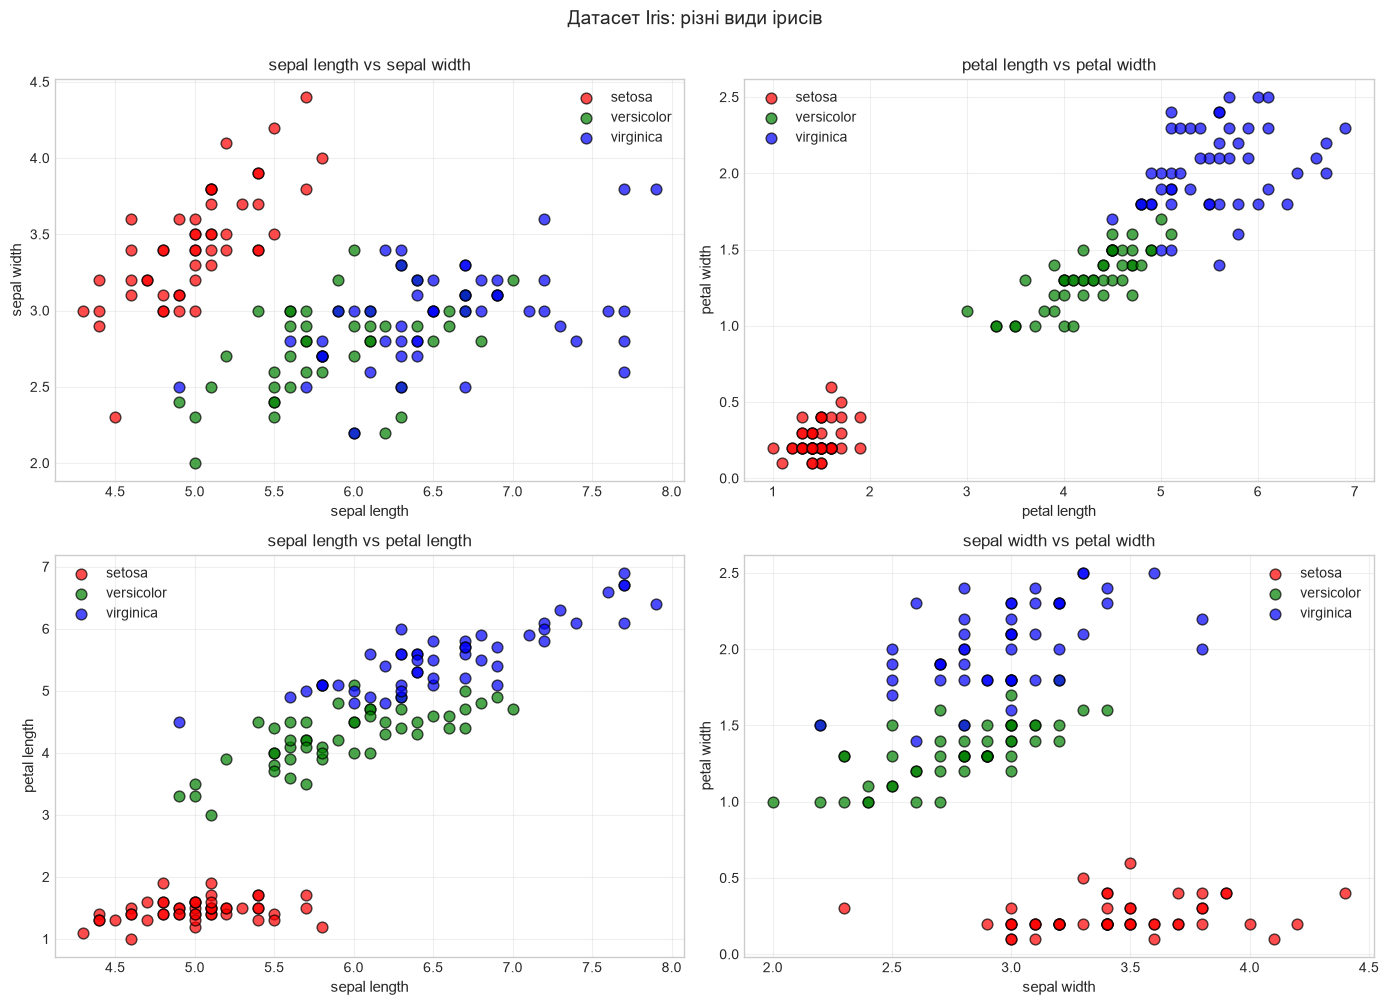

In [4]:
# Візуалізація: 4 графіки для різних пар ознак
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = ['red', 'green', 'blue']
species_names = ['setosa', 'versicolor', 'virginica']

# Вибір пар ознак для графіків
pairs = [
    (0, 1, 'sepal length', 'sepal width'),
    (2, 3, 'petal length', 'petal width'),
    (0, 2, 'sepal length', 'petal length'),
    (1, 3, 'sepal width', 'petal width')
]

for i, (j1, j2, name1, name2) in enumerate(pairs):
    ax = axes[i // 2, i % 2]
    for species_id in range(3):
        mask = y == species_id
        ax.scatter(X[mask, j1], X[mask, j2],
                   color=colors[species_id],
                   label=species_names[species_id],
                   s=60, alpha=0.7, edgecolor='black')
    ax.set_xlabel(name1, fontsize=11)
    ax.set_ylabel(name2, fontsize=11)
    ax.set_title(f'{name1} vs {name2}', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle('Датасет Iris: різні види ірисів', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

### Що ми бачимо на графіках?

Зверніть увагу на графік **petal length vs petal width** (правий верхній):
- **Червоні точки (setosa)** утворюють **окрему групу** в лівому нижньому куті.
- **Зелені (versicolor)** та **сині (virginica)** трохи перекриваються, але теж добре розділені.

Це означає, що ознаки **довжина та ширина пелюстки** — найінформативніші. Модель дерева рішень, ймовірно, використає їх першими для розділення.

### Розділення даних на навчальну та тестову вибірки

Перед навчанням моделі ми завжди розділяємо дані:
- **Навчальна вибірка** (80%) — на ній модель вчиться.
- **Тестова вибірка** (20%) — на ній перевіряємо, як модель працює на нових даних.

In [5]:
# Розділення даних
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Розмір навчальної вибірки: {X_train.shape[0]} зразків")
print(f"Розмір тестової вибірки: {X_test.shape[0]} зразків")

Розмір навчальної вибірки: 120 зразків
Розмір тестової вибірки: 30 зразків


### Навчання моделі дерева рішень

Створимо модель та навчимо її на навчальних даних.

In [6]:
# Створення та навчання моделі
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_train, y_train)

# Прогноз на тестових даних
y_pred = clf.predict(X_test)

# Оцінка якості
accuracy = accuracy_score(y_test, y_pred)
print(f"Точність моделі на тестових даних: {accuracy:.2%}")

Точність моделі на тестових даних: 100.00%


### Візуалізація дерева рішень

Найцікавіше — подивитися, як саме модель приймає рішення! Для цього використаємо `plot_tree`.

На графіку ми побачимо:
- **Вузли** — це запитання (наприклад, «чи довжина пелюстки менша за 2.45 см?»).
- **Гілки** — це відповіді «так» або «ні».
- **Листки** — це кінцевий прогноз (вид ірису).
- **Значення** — скільки зразків потрапило в цей вузол і як вони розподілені за класами.

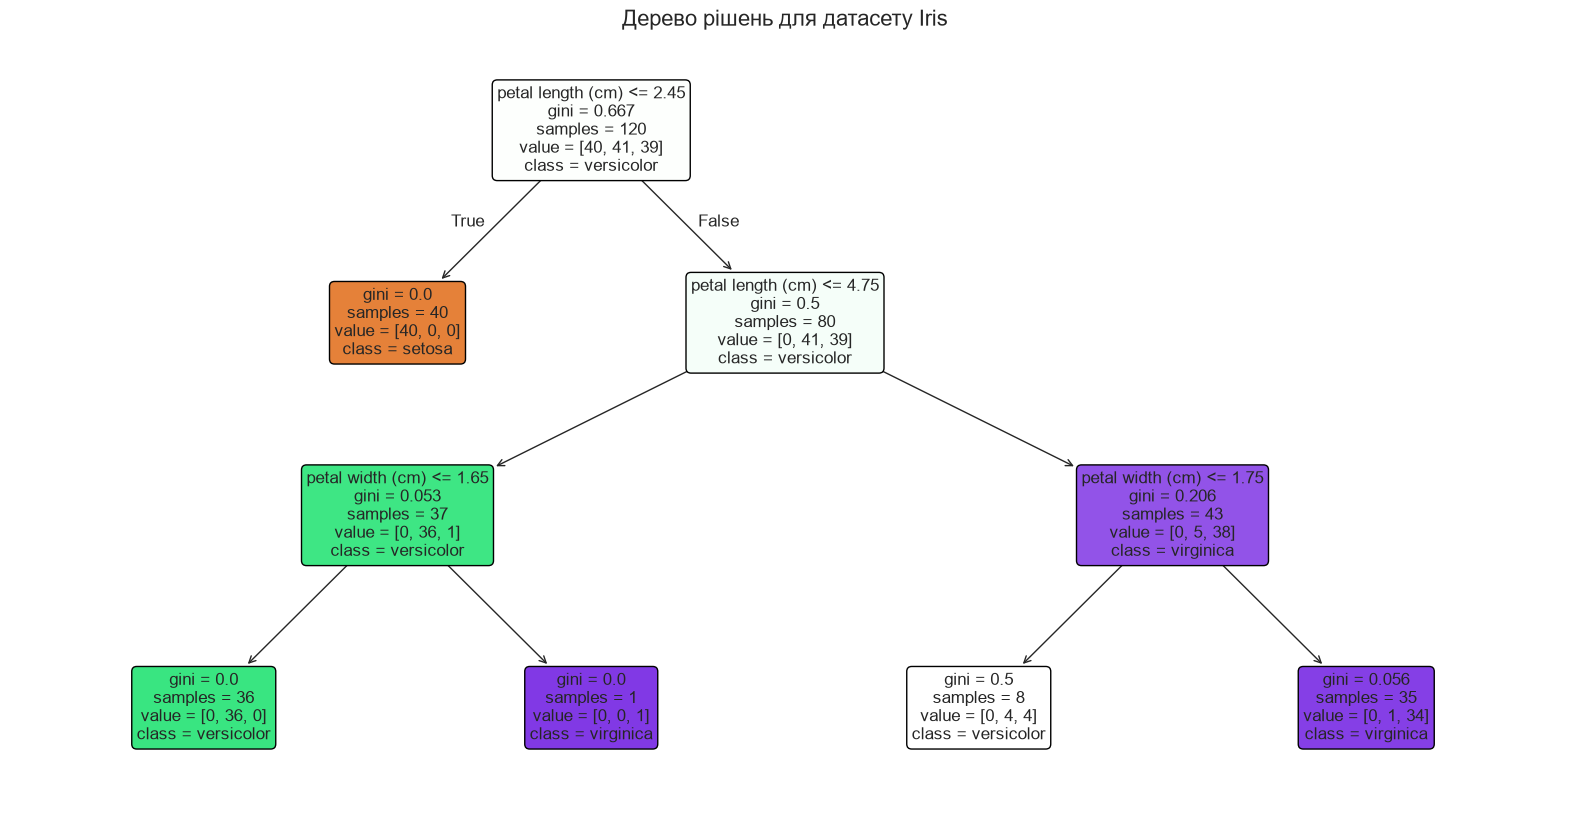

In [7]:
# Візуалізація дерева рішень
plt.figure(figsize=(20, 10))
plot_tree(clf,
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          filled=True,
          rounded=True,
          fontsize=12)
plt.title("Дерево рішень для датасету Iris", fontsize=16)
plt.show()

### Як читати дерево?

Подивіться на **кореневий вузол** (найвищий):
- **Умова**: `petal length (cm) <= 2.45` — це перше запитання, яке ставить модель.
- **gini = 0.667** — це міра «нечистоти» вузла. Чим менше, тим краще.
- **samples = 120** — стільки зразків потрапило в цей вузол.
- **value = [40, 40, 40]** — розподіл зразків за класами.
- **class = setosa** — прогноз для більшості зразків у цьому вузлі.

Якщо умова виконується (гілка «True»), ми йдемо вліво — і потрапляємо на листок, де всі 40 зразків — це **setosa**. Це означає, що модель може впевнено класифікувати цей вид.

Якщо умова не виконується (гілка «False»), ми йдемо вправо — і там продовжуємо задавати запитання, щоб розрізнити **versicolor** та **virginica**.

### Текстове представлення дерева

Окрім графічного зображення, можна подивитися на дерево у вигляді тексту за допомогою `export_text`.

In [8]:
# Текстове представлення дерева
tree_rules = export_text(clf, feature_names=list(iris.feature_names))
print(tree_rules)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal length (cm) <= 4.75
|   |   |--- petal width (cm) <= 1.65
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.65
|   |   |   |--- class: 2
|   |--- petal length (cm) >  4.75
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- class: 2



---
## Крок 3. Проблема перенавчання (Overfitting)

Що буде, якщо ми дозволимо дереву рости без обмежень? Воно просто «запам'ятає» всі навчальні дані, але на нових даних працюватиме погано. Це називається **перенавчанням** (overfitting).

**Ознаки перенавчання**:
- Точність на навчальних даних = 100%
- Точність на тестових даних — значно нижча

Щоб цього уникнути, використовують **обмеження** (регуляризацію):
- `max_depth` — максимальна глибина дерева.
- `min_samples_leaf` — мінімальна кількість зразків у листку.
- `min_samples_split` — мінімальна кількість зразків для розділення вузла.

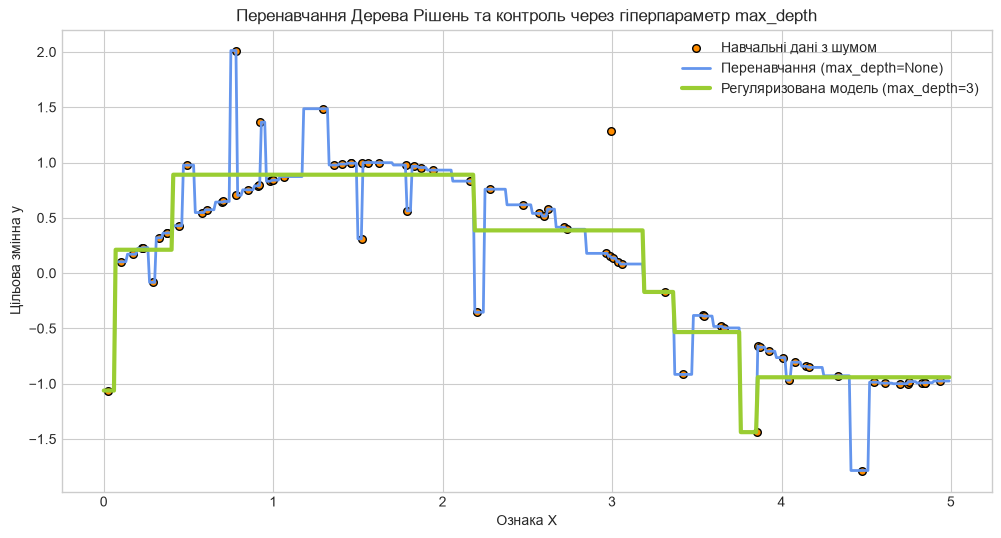

In [9]:
# Генерація синтетичних даних із шумом
np.random.seed(42)
X_syn = np.sort(5 * np.random.rand(80, 1), axis=0)
y_syn = np.sin(X_syn).ravel()
y_syn[::5] += 3 * (0.5 - np.random.rand(16)) # Додаємо випадковий шум

# Навчання двох моделей: без обмежень (перенавчання) та з регуляризацією
tree_overfitted = DecisionTreeRegressor(max_depth=None) # Глибина не обмежена
tree_regularized = DecisionTreeRegressor(max_depth=3)   # Обмежуємо глибину для запобігання перенавчанню

tree_overfitted.fit(X_syn, y_syn)
tree_regularized.fit(X_syn, y_syn)

# Дані для побудови ліній прогнозів
X_test_syn = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]

# Візуалізація результатів
plt.figure(figsize=(12, 6))
plt.scatter(X_syn, y_syn, s=30, edgecolor="black", c="darkorange", label="Навчальні дані з шумом")
plt.plot(X_test_syn, tree_overfitted.predict(X_test_syn), color="cornflowerblue", label="Перенавчання (max_depth=None)", linewidth=2)
plt.plot(X_test_syn, tree_regularized.predict(X_test_syn), color="yellowgreen", label="Регуляризована модель (max_depth=3)", linewidth=3)

plt.xlabel("Ознака X")
plt.ylabel("Цільова змінна y")
plt.title("Перенавчання Дерева Рішень та контроль через гіперпараметр max_depth")
plt.legend()
plt.show()

### Що ми бачимо?

Тепер картина ще яскравіша:
- Модель **без обмежень** ідеально запам'ятала маленьку навчальну вибірку (100%), але погано працює на нових даних.
- Модель **з обмеженням** (max_depth=2) гірша на навчанні, але краще узагальнює.

**Ключовий висновок**: чим менше даних, тим більша ймовірність перенавчання. Для маленьких вибірок обмеження складності моделі — обов'язкове!



### Головне правило

> **Перенавчання виникає, коли модель показує високу точність на навчанні, але значно нижчу — на тестових даних.**

У таких випадках потрібно:
1. **Обмежити складність моделі** (`max_depth`, `min_samples_leaf`).
2. **Збільшити кількість даних** для навчання.
3. **Зменшити шум** у даних (покращити якість вимірювань).

In [10]:
# # Візуалізація дерева
# plt.figure(figsize=(22, 12))
# plot_tree(clf_cancer_limited,
#           feature_names=cancer.feature_names,
#           class_names=cancer.target_names,
#           filled=True,
#           rounded=True,
#           fontsize=9,
#           max_depth=3)
# plt.title("Дерево рішень для Breast Cancer (перші 3 рівні)", fontsize=16)
# plt.show()

NameError: name 'clf_cancer_limited' is not defined

<Figure size 2200x1200 with 0 Axes>

---
# Практичні завдання

Тепер давайте перевіримо ваші знання! Виконайте завдання нижче у порожніх комірках.

**Не забудьте використовувати:**
- `DecisionTreeClassifier()` для створення моделі,
- `model.fit(X, y)` для навчання,
- `model.predict(X_new)` для прогнозу,
- `plot_tree()` для візуалізації,
- `accuracy_score()` для оцінки точності.

## Завдання 1: Дерево рішень для регресії (California Housing)

**Умова:**
1. Завантажити датасет California Housing та візуалізувати географічний розподіл цін.
2. Розділити дані на навчальну і тестову вибірки (80/20, random_state=42).
3. Навчити модель DecisionTreeRegressor(max_depth=5, random_state=42).
4. Обчислити R² на тестовій вибірці.
5. Намалювати важливість ознак (feature_importances_) у вигляді горизонтальної діаграми.

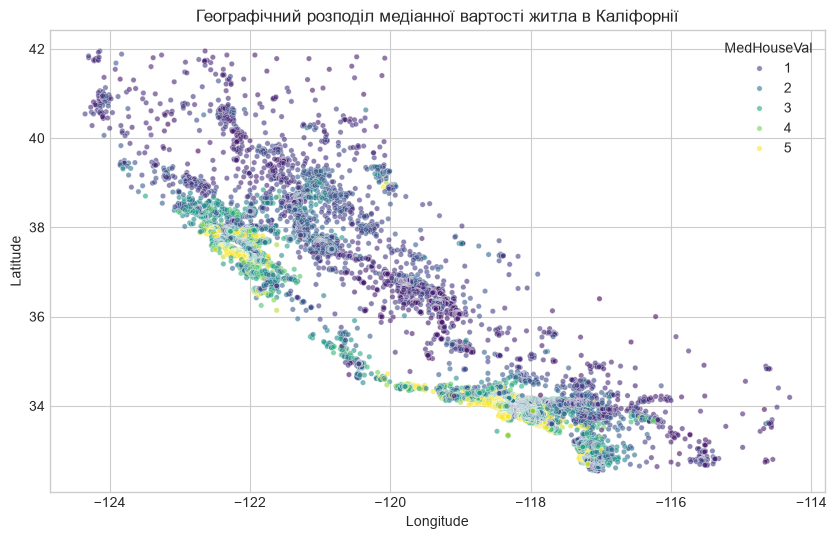

In [11]:
# Завантаження даних
housing = fetch_california_housing(as_frame=True)
df_housing = housing.frame
X = housing.data
y = housing.target
feature_names = housing.feature_names

# Візуалізація датасету: Географічний розподіл вартості житла
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_housing, x='Longitude', y='Latitude', hue='MedHouseVal',
                palette='viridis', alpha=0.6, s=15)
plt.title('Географічний розподіл медіанної вартості житла в Каліфорнії')
plt.show()


R² Score (Decision Tree): 0.5997


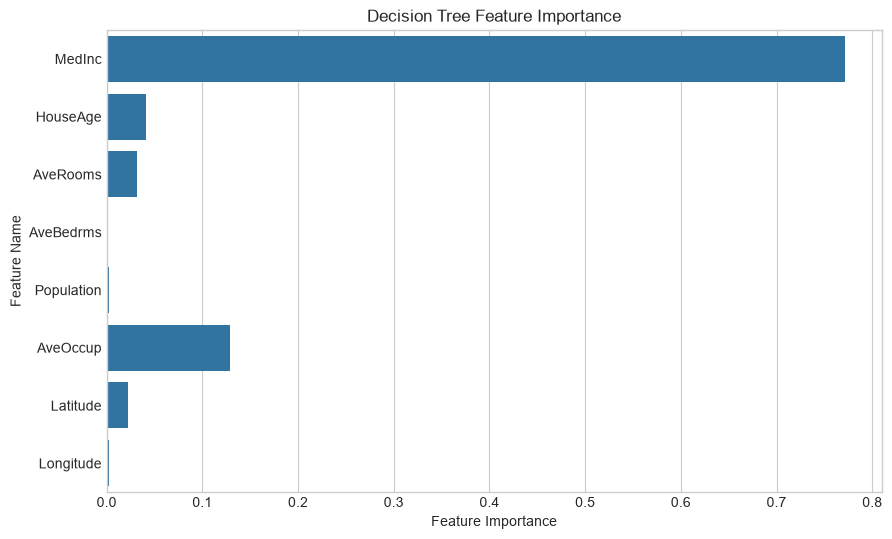

In [12]:
# Розділення
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Навчання дерева рішень DecisionTreeRegressor (обмежуємо max_depth щоб уникнути перенавчання)
dt_reg = DecisionTreeRegressor(max_depth=5)
dt_reg.fit(X_train, y_train)
y_pred = dt_reg.predict(X_test)
dt_r2 = r2_score(y_test, y_pred)

# Оцінка моделі

print(f"R² Score (Decision Tree): {dt_r2:.4f}")

# Важливість ознак (seaborn barplot)
importance = dt_reg.feature_importances_
features = [f"Features {i+1}" for i in range(X.shape[1])]
feature_names = housing.feature_names

plt.figure(figsize=(10, 6))
sns.barplot(x=importance, y=feature_names, orient="h")
plt.xlabel("Feature Importance")
plt.ylabel("Feature Name")
plt.title("Decision Tree Feature Importance")
plt.show()


## Завдання 2: Випадковий ліс vs Дерево рішень

**Умова:**
1. Використати ті самі дані.
2. Навчити RandomForestRegressor(n_estimators=100, random_state=42).
3. Обчислити R² на тестовій вибірці.
4. Порівняти з деревом рішень (Завдання 1) у таблиці.

In [13]:
# Випадковий ліс
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)
y_pred1 = rf_reg.predict(X_test)
rf_r2 = r2_score(y_test, y_pred1)

# Таблиця порівняння
comparison_df = pd.DataFrame({
    'Модель': ['Decision Tree (max_depth=5)', 'Random Forest (n=100)'],
    'R² Score': [dt_r2, rf_r2]
})
display(comparison_df)

,Модель,R² Score
0,Decision Tree (max_depth=5),0.599732
1,Random Forest (n=100),0.804624


## Завдання 3: Градієнтний бустинг (XGBoost)

**Умова:**
1. Використати ті самі дані.
2. Навчити XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42).
3. Обчислити R² на тестовій вибірці.
4. Порівняти з Random Forest.
5. Зробити висновок.

In [14]:
from xgboost import XGBRegressor

# XGBoost
xgb_reg = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
xgb_reg.fit(X_train, y_train)
y_pred2 = xgb_reg.predict(X_test)
xgb_r2 = r2_score(y_test, y_pred2)

# Порівняння
comparison_df.loc[2] = ['XGBoost (n=200, lr=0.1)', xgb_r2]
display(comparison_df)


,Модель,R² Score
0,Decision Tree (max_depth=5),0.599732
1,Random Forest (n=100),0.804624
2,"XGBoost (n=200, lr=0.1)",0.833925


**Висновок:**
Ансамблеві методи (Random Forest та XGBoost) показують значно кращі результати
порівняно з одним деревом рішень. XGBoost зазвичай дозволяє досягти найвищої точності
завдяки послідовному виправленню помилок (бустингу).

## Завдання 4: Логістична регресія на датасеті Breast Cancer

**Умова:**
1. Завантажити датасет Breast Cancer (load_breast_cancer) та візуалізувати частину даних.
2. Розділити дані на навчальну і тестову вибірки (80/20, random_state=42).
3. Навчити модель LogisticRegression(max_iter=3000).
4. Отримати передбачення на тестовій вибірці.
5. Побудувати confusion matrix і вивести метрики: Accuracy, Precision, Recall, F1.

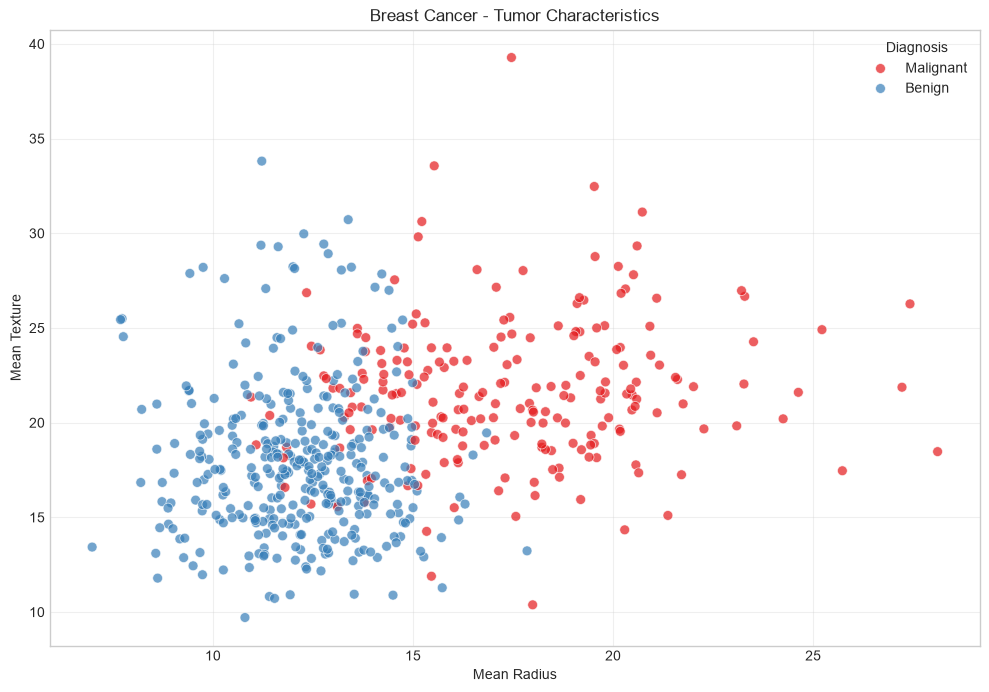

In [15]:
# Завантаження даних Breast Cancer
cancer = load_breast_cancer(as_frame=True)
df_cancer = cancer.frame
X_c = cancer.data
y_c = cancer.target

# Візуалізація: побудувати scatterplot Розподіл класів за двома ознаками - Радіус ('mean radius') та Текстура ('mean texture')
# "Розподіл класів пухлин (Злоякісні vs Доброякісні)"
df_cancer["Diagnosis"] = df_cancer["target"].map({
    0: "Malignant",
    1: "Benign"
})
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df_cancer,
    x="mean radius",
    y="mean texture",
    hue="Diagnosis",
    palette="Set1",
    alpha=0.7,
    s=50
)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer - Tumor Characteristics")
plt.legend(title="Diagnosis")
plt.grid(alpha=0.3)

plt.show()

In [17]:
# Розділення
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.2, random_state=42)

# Логістична регресія (збільшуємо max_iter для збіжності)
log_reg = LogisticRegression(max_iter=30000, random_state=42)
log_reg.fit(Xc_train, yc_train)
yc_pred = log_reg.predict(Xc_test)


Цей warning виникає через те, що градієнтний алгоритм оптимізації lbfgs не встигає знайти мінімум функції втрат за відведену кількість ітерацій (max_iter).

Головна причина для датасету Breast Cancer — різний масштаб ознак.

Деякі ознаки в цьому датасеті мають дуже великі значення (наприклад, mean area сягає більше 1000), а інші — дуже малі (mean smoothness становить близько 0.1). Через таку розбіжність у масштабах поверхня функції втрат стає дуже витягнутою, і градієнтний спуск робить дрібні «зигзагоподібні» кроки, повертаючи помилку про досягнення ліміту ітерацій.

In [18]:
from sklearn.pipeline import make_pipeline

# Створення пайплайну: спочатку масштабування, потім модель
model_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)
model_pipeline.fit(Xc_train, yc_train)
yc_pred = model_pipeline.predict(Xc_test)

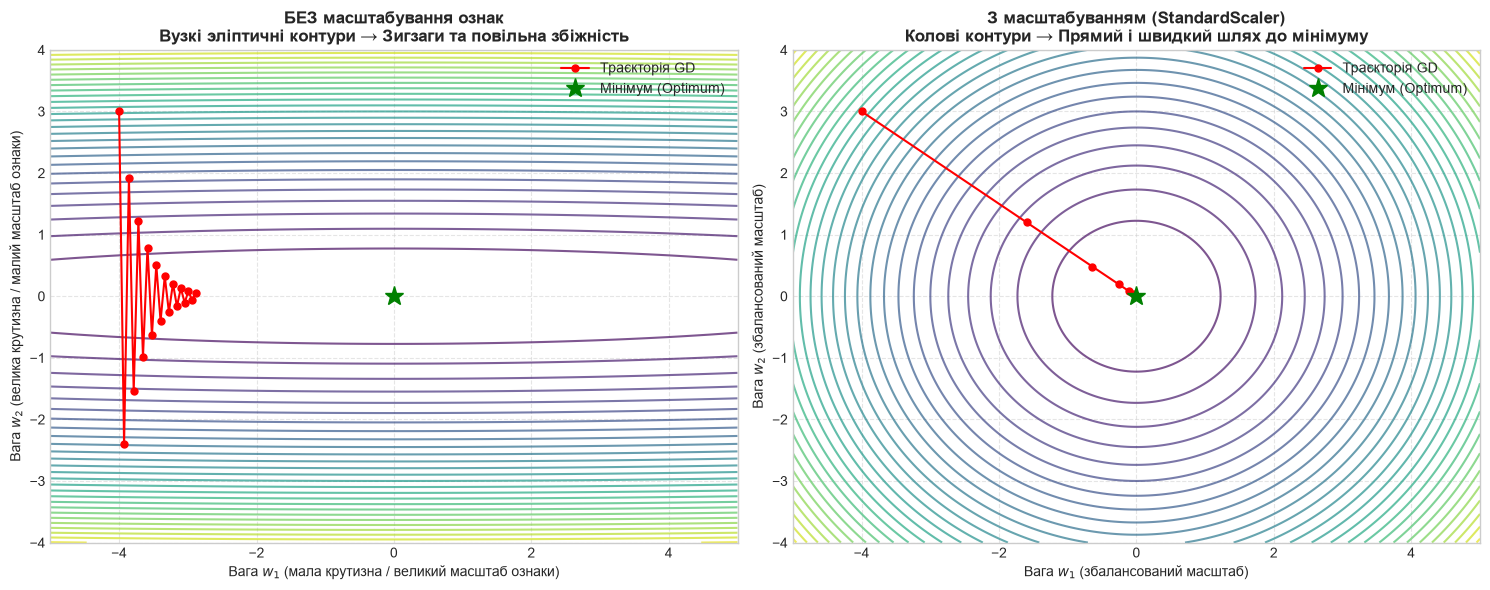

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. Визначення математичних моделей функції втрат та їх градієнтів
# -----------------------------------------------------------------------------

# А) Немасштабовані дані: поверхня дуже витягнута (коефіцієнти 0.1 та 10.0)
def loss_unscaled(w1, w2):
    return 0.1 * w1**2 + 10.0 * w2**2

def grad_unscaled(w1, w2):
    return np.array([0.2 * w1, 20.0 * w2])

# Б) Масштабовані дані (StandardScaler): симетрична поверхня (параболоїд обертання)
def loss_scaled(w1, w2):
    return 1.0 * w1**2 + 1.0 * w2**2

def grad_scaled(w1, w2):
    return np.array([2.0 * w1, 2.0 * w2])

# -----------------------------------------------------------------------------
# 2. Функція оптимізації Градієнтним Спуском (Gradient Descent)
# -----------------------------------------------------------------------------
def run_gradient_descent(grad_func, start_point, lr, n_steps=18):
    trajectory = [np.array(start_point, dtype=float)]
    p = np.array(start_point, dtype=float)
    for _ in range(n_steps):
        g = grad_func(p[0], p[1])
        p = p - lr * g  # Крок у напрямку, протилежному градієнту
        trajectory.append(p.copy())
    return np.array(trajectory)

# Параметри оптимізації
start_point = [-4.0, 3.0]
n_steps = 18

# Траєкторії для двох випадків
traj_unscaled = run_gradient_descent(grad_unscaled, start_point, lr=0.09, n_steps=n_steps)
traj_scaled = run_gradient_descent(grad_scaled, start_point, lr=0.3, n_steps=n_steps)

# -----------------------------------------------------------------------------
# 3. Візуалізація результатів (Contour Plots)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Сітка для побудови ліній рівня (контурів)
w1_grid = np.linspace(-5, 5, 200)
w2_grid = np.linspace(-4, 4, 200)
W1, W2 = np.meshgrid(w1_grid, w2_grid)

# --- Лівий графік: БЕЗ масштабування ---
Z_unscaled = loss_unscaled(W1, W2)
axes[0].contour(W1, W2, Z_unscaled, levels=30, cmap='viridis', alpha=0.7)
axes[0].plot(traj_unscaled[:, 0], traj_unscaled[:, 1], 'ro-', markersize=5, linewidth=1.5, label='Траєкторія GD')
axes[0].plot(0, 0, 'g*', markersize=14, label='Мінімум (Optimum)')
axes[0].set_title('БЕЗ масштабування ознак\nВузкі эліптичні контури → Зигзаги та повільна збіжність', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Вага $w_1$ (мала крутизна / великий масштаб ознаки)', fontsize=10)
axes[0].set_ylabel('Вага $w_2$ (велика крутизна / малий масштаб ознаки)', fontsize=10)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Правий графік: З масштабуванням (StandardScaler) ---
Z_scaled = loss_scaled(W1, W2)
axes[1].contour(W1, W2, Z_scaled, levels=30, cmap='viridis', alpha=0.7)
axes[1].plot(traj_scaled[:, 0], traj_scaled[:, 1], 'ro-', markersize=5, linewidth=1.5, label='Траєкторія GD')
axes[1].plot(0, 0, 'g*', markersize=14, label='Мінімум (Optimum)')
axes[1].set_title('З масштабуванням (StandardScaler)\nКолові контури → Прямий і швидкий шлях до мінімуму', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Вага $w_1$ (збалансований масштаб)', fontsize=10)
axes[1].set_ylabel('Вага $w_2$ (збалансований масштаб)', fontsize=10)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Accuracy:  0.9737
Precision: 0.9722
Recall:    0.9859
F1 Score:  0.9790


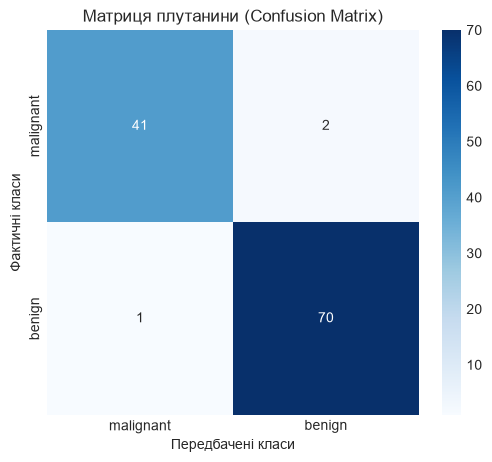

In [20]:
# Метрики
print(f"Accuracy:  {accuracy_score(yc_test, yc_pred):.4f}")
print(f"Precision: {precision_score(yc_test, yc_pred):.4f}")
print(f"Recall:    {recall_score(yc_test, yc_pred):.4f}")
print(f"F1 Score:  {f1_score(yc_test, yc_pred):.4f}")

# Матриця плутанини (Confusion Matrix)
cm = confusion_matrix(yc_test, yc_pred)

# Візуалізація confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.title('Матриця плутанини (Confusion Matrix)')
plt.xlabel('Передбачені класи')
plt.ylabel('Фактичні класи')
plt.show()

---
## Завдання 5 (додаткове). Власний датасет

**Умова:**
Уявіть, що ви аналітик у фітнес-клубі. Ви маєте дані про клієнтів:

| Вік | Тренувань на тиждень | Харчування (1-10) | Здоров'я (0-1) |
|---|---|---|---|
| 25 | 5 | 8 | 1 |
| 30 | 3 | 6 | 1 |
| 45 | 1 | 4 | 0 |
| 35 | 4 | 7 | 1 |
| 50 | 2 | 3 | 0 |
| 28 | 6 | 9 | 1 |
| 40 | 2 | 5 | 0 |
| 55 | 1 | 2 | 0 |

**Завдання:**
1. Створіть DataFrame з цими даними.
2. Розділіть на X та y (y — колонка «Здоров'я»).
3. Навчіть модель дерева рішень.
4. Передбачте здоров'я для нового клієнта: вік 32, 4 тренування на тиждень, харчування 7.
5. Візуалізуйте дерево та поясніть, які ознаки найважливіші.

[1]


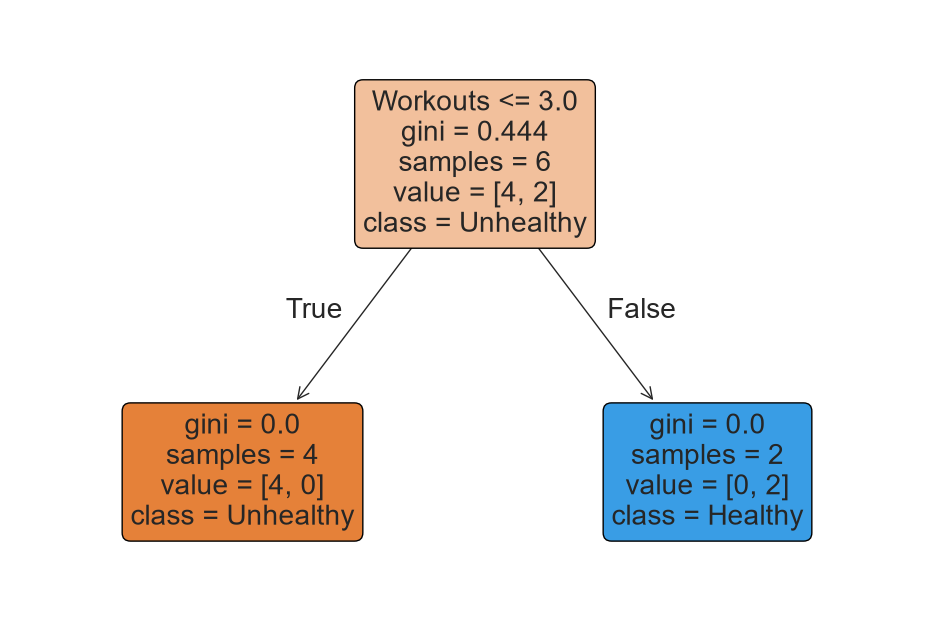

In [36]:

from sklearn import tree

data = {
    "Age": [25, 30, 45, 35, 50, 28, 40, 55],
    "Workouts": [5, 3, 1, 4, 2, 6, 2, 1],
    "Nutrition": [8, 6, 4, 7, 3, 9, 5, 2],
    "Health": [1, 1, 0, 1, 0, 1, 0, 0]
}
# display(df_fitness.style.hide(axis="index"))
df_fitness = pd.DataFrame(data)
X = df_fitness[['Age', 'Workouts', 'Nutrition']]
y = df_fitness['Health']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

new_client = pd.DataFrame({
    "Age": [32],
    "Workouts": [4],
    "Nutrition": [7]
})

prediction = model.predict(new_client)
print(prediction)

plt.figure(figsize=(12, 8))
tree.plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Unhealthy", "Healthy"],
    filled=True,
    rounded=True,
    fontsize=20
)
plt.show()



